# 1주차 실습. 물성 예측 모델 여러 개 비교하기

**목표**: 같은 데이터, 같은 분할에서 모델 6개를 돌려 **결과표 한 장**을 만든다.

| 단계 | 내용 | 이 노트북에서 |
|---|---|---|
| 1 | 데이터 불러오기 | `1.PropertyDB/<물성>.csv` |
| 2 | 전처리 확인 | 무효 SMILES, 중복, 분포 |
| 3 | 임베딩 (분자 → 숫자 벡터) | RDKit descriptor, Morgan fingerprint |
| 4 | 데이터 분할 | random split, scaffold split |
| 5 | 모델링 | Ridge, kNN, SVR, Random Forest, XGBoost, MLP |
| 6 | 평가 | MAE, RMSE, R², parity plot |

**팀별로 바꿀 곳은 바로 아래 셀의 `PROP` 하나뿐이다.**
GNN(GIN)은 2주차에 이 결과표에 한 줄을 추가하는 방식으로 다룬다.

In [1]:
PROP = 'mp'          # 팀 물성: logP, logSolubility, logPvap, bp, mp, density, pKa ...
MAX_N = 5000         # 수업 시간용 상한. 전체를 쓰려면 None (SVR이 느려진다)
SEED = 42
DB_DIR = 'data'

## 0. 준비
필요한 패키지: `rdkit`, `scikit-learn`, `xgboost`, `pandas`, `matplotlib`.
설치가 안 되어 있으면 `conda install -c conda-forge rdkit xgboost scikit-learn` 한 번이면 된다.

In [2]:
import time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, rdFingerprintGenerator
from rdkit.Chem.Scaffolds import MurckoScaffold
RDLogger.DisableLog('rdApp.*')
warnings.filterwarnings('ignore')
plt.rcParams.update({'font.size': 12, 'axes.grid': False})

In [3]:
# [추가 — mp 팀] 노트북이 그리는 그림을 results_nb_mp/ 에 PNG 로도 저장한다. 교수님 코드와 결과에는 영향 없음.
import os
OUT = 'results_nb_mp'; os.makedirs(OUT, exist_ok=True)
_FIG_NAMES = iter(['fig01_mp_hist', 'fig02_parity_random_MorganFP', 'fig03_parity_scaffold_MorganFP',
                   'fig04_bar_random_vs_scaffold', 'fig05_parity_random_Descriptor', 'fig06_parity_scaffold_Descriptor'])
_orig_show = plt.show
def _show_and_save(*a, **k):
    name = next(_FIG_NAMES, None) or f'fig_extra_{int(time.time() * 1000) % 100000}'
    plt.gcf().savefig(f'{OUT}/{name}.png', dpi=150, bbox_inches='tight')
    return _orig_show(*a, **k)
plt.show = _show_and_save

## 1. 데이터 불러오기
CSV 한 줄이 분자 하나다. `smiles`는 분자 구조를 글자로 쓴 것이고, `value`가 맞혀야 할 물성값이다.

In [4]:
df = pd.read_csv(f'{DB_DIR}/{PROP}.csv')
unit = df['unit'].iloc[0] if 'unit' in df else ''
print(f'{PROP}: {len(df):,} molecules, unit = {unit}')
if MAX_N and len(df) > MAX_N:
    df = df.sample(MAX_N, random_state=SEED).reset_index(drop=True)
    print(f'수업용으로 {MAX_N:,}개만 무작위 추출')
df.head()

mp: 19,945 molecules, unit = K
수업용으로 5,000개만 무작위 추출


,smiles,value,unit,source
0,CC#C[C@]1(O)CC[C@H]2[C@@H]3CCC4=CC(=O)CCC4=C3[...,466.65,K,Bradley_ONS_MP
1,CCCCCCCCc1ccc(C(=O)O)cc1,371.15,K,Bradley_ONS_MP
2,CC(Oc1ccc(Oc2nc3ccc(Cl)cc3o2)cc1)C(=O)O,431.15,K,Bradley_ONS_MP
3,O=C(O)/C=C/c1cc(F)cc(F)c1,478.15,K,Bradley_ONS_MP
4,CC(C(N)=O)n1nc2ccccc2n1,442.65,K,Bradley_ONS_MP


## 2. 전처리 확인
DB를 만들 때 이미 정리했지만, **남이 준 데이터는 항상 직접 확인한다.**

1. SMILES가 RDKit에서 읽히는가 (무효 SMILES)
2. 같은 분자가 두 번 있지 않은가 (중복)
3. 값 분포가 한쪽으로 몰려 있지 않은가 (몰려 있으면 log 변환을 고려)

무효 SMILES : 0
중복 SMILES : 0


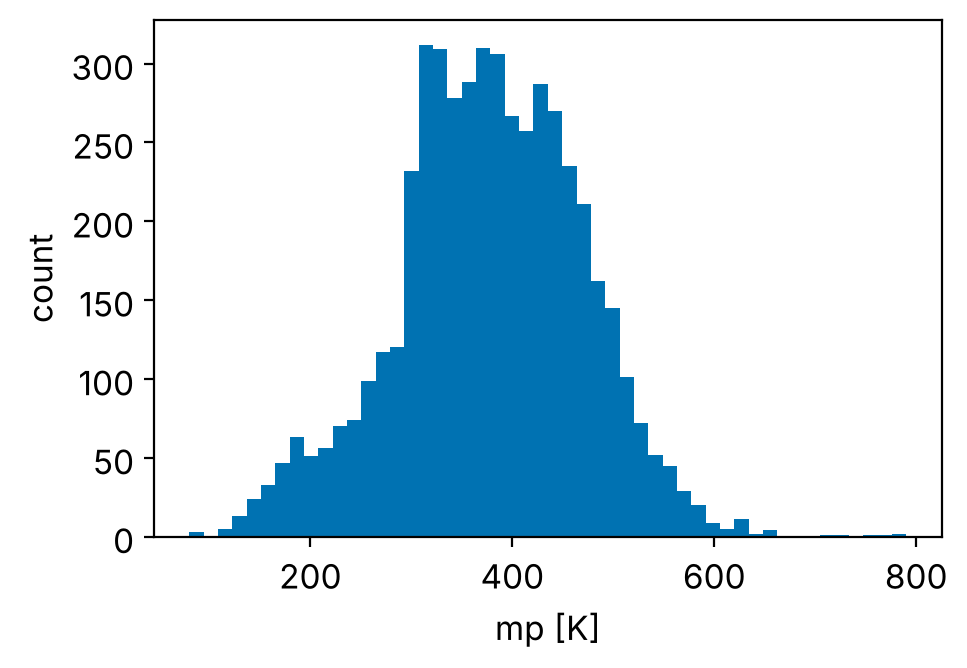

count    5000.000000
mean      377.418888
std        92.299444
min        80.150000
25%       319.150000
50%       378.150000
75%       441.150000
max       790.150000
Name: value, dtype: float64

In [5]:
df['mol'] = df['smiles'].apply(Chem.MolFromSmiles)
print('무효 SMILES :', df['mol'].isna().sum())
print('중복 SMILES :', df['smiles'].duplicated().sum())
df = df[df['mol'].notna()].reset_index(drop=True)

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.hist(df['value'], bins=50, color='#0072B2')
ax.set_xlabel(f'{PROP} [{unit}]'); ax.set_ylabel('count')
plt.tight_layout(); plt.show()
df['value'].describe()

## 3. 임베딩: 분자를 숫자 벡터로 바꾸기
모델은 SMILES 글자를 직접 읽지 못한다. 분자 하나를 **고정 길이 숫자 벡터 하나**로 바꿔야 한다.

| 표현 | 무엇을 담나 | 길이 | 특징 |
|---|---|---|---|
| **RDKit descriptor** | 분자량, TPSA, 회전 가능 결합 수, 고리 수 등 사람이 정의한 물리화학 값 | 약 210 | 해석이 쉽다. 값 크기가 제각각이라 스케일링이 필요하다 |
| **Morgan fingerprint (ECFP4)** | 원자 주변 반경 2 이내 부분구조가 있으면 1, 없으면 0 | 2048 | 구조를 넓게 담는다. 비트 하나의 의미는 흐리다 |
| 분자 그래프 (2주차) | 원자 = 노드, 결합 = 엣지, 원자마다 74개 특징 | 분자마다 다름 | GNN이 직접 학습한다 |

> 생각해볼 것: `logP`를 예측하는데 descriptor 안에 RDKit이 계산한 `MolLogP`가 들어 있다. 이건 공정한 비교인가?

In [6]:
desc_names = [n for n, _ in Descriptors.descList]
def rdkit_desc(m):
    return [f(m) for _, f in Descriptors.descList]

t0 = time.time()
X_desc = np.array([rdkit_desc(m) for m in df['mol']], dtype=float)
X_desc = np.nan_to_num(X_desc, nan=0.0, posinf=0.0, neginf=0.0)
X_desc = np.clip(X_desc, -1e6, 1e6)
print(f'descriptor: {X_desc.shape}  ({time.time()-t0:.1f} s)')

mfp = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
X_fp = np.array([mfp.GetFingerprintAsNumPy(m) for m in df['mol']], dtype=np.uint8)
print(f'Morgan FP : {X_fp.shape}, 분자당 켜진 비트 평균 {X_fp.sum(1).mean():.1f}개')

y = df['value'].values

descriptor: (5000, 217)  (30.0 s)
Morgan FP : (5000, 2048), 분자당 켜진 비트 평균 25.9개


## 4. 데이터 분할: random vs scaffold
- **random split**: 무작위로 80%는 학습, 20%는 시험. 비슷한 분자가 양쪽에 다 들어가서 성능이 좋게 나온다.
- **scaffold split**: 분자의 뼈대(Murcko scaffold)가 같은 것끼리 묶고, **시험 세트에는 학습 때 못 본 뼈대만** 넣는다. 새 분자를 스크리닝하는 실제 상황에 더 가깝다.

시험 세트는 마지막 평가에만 쓴다. 하이퍼파라미터를 시험 세트 성능을 보고 고르면 그 순간 누수(leakage)다.

In [7]:
from sklearn.model_selection import train_test_split

def random_split(n, test=0.2, seed=SEED):
    return train_test_split(np.arange(n), test_size=test, random_state=seed)

def scaffold_split(mols, test=0.2, seed=SEED):
    groups = {}
    for i, m in enumerate(mols):
        s = MurckoScaffold.MurckoScaffoldSmiles(mol=m, includeChirality=False)
        groups.setdefault(s, []).append(i)
    # 큰 scaffold 묶음은 학습으로, 작은 묶음(희귀한 뼈대)부터 시험으로
    sets = sorted(groups.values(), key=len)
    rng = np.random.default_rng(seed); rng.shuffle(sets)
    sets = sorted(sets, key=len)
    n_test = int(test * len(mols)); te = []
    for g in sets:
        if len(te) + len(g) > n_test: continue
        te += g
    tr = np.setdiff1d(np.arange(len(mols)), te)
    return tr, np.array(te)

splits = {'random': random_split(len(df)), 'scaffold': scaffold_split(df['mol'])}
for k, (tr, te) in splits.items():
    print(f'{k:8s}: train {len(tr):,} / test {len(te):,}')

random  : train 4,000 / test 1,000
scaffold: train 4,000 / test 1,000


## 5. 모델 6개
| 모델 | 한 줄 직관 | 스케일링 |
|---|---|---|
| **Ridge** | 특징의 가중합. 가장 단순한 기준선 | 필요 |
| **kNN** | 가장 비슷한 분자 k개의 평균 | 필요 |
| **SVR** | 커널로 비선형 관계를 잡는 회귀. 데이터가 많으면 느리다 | 필요 |
| **Random Forest** | 결정 트리 여러 개의 평균. 튜닝 없이도 잘 된다 | 불필요 |
| **XGBoost** | 앞 트리의 오차를 다음 트리가 고친다 | 불필요 |
| **MLP** | 완전연결 신경망. GNN으로 가는 다리 | 필요 |

모든 모델을 같은 `Pipeline` 형식으로 묶어 두면 비교 코드가 한 줄로 끝난다.

In [8]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor

def get_models():
    return {
        'Ridge':        make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
        'kNN':          make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=5, weights='distance')),
        'SVR':          make_pipeline(StandardScaler(), SVR(C=10, epsilon=0.1)),
        'RandomForest': RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=SEED),
        'XGBoost':      XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=6,
                                     subsample=0.8, colsample_bytree=0.5, n_jobs=-1, random_state=SEED),
        'MLP':          make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(256, 128), alpha=1e-3,
                                     early_stopping=True, max_iter=300, random_state=SEED)),
    }

## 6. 학습과 평가
평가 지표는 세 가지다.
- **MAE**: 평균 절대 오차. 단위가 물성과 같아서 직관적이다 (예: logP 0.5 차이)
- **RMSE**: 큰 오차에 벌점을 더 준다. MAE보다 많이 크면 크게 틀린 분자가 있다는 뜻이다
- **R²**: 1이면 완벽, 0이면 평균값으로 찍는 것과 같다

In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

features = {'Descriptor': X_desc, 'MorganFP': X_fp}
rows, preds = [], {}
for split_name, (tr, te) in splits.items():
    for feat_name, X in features.items():
        for model_name, model in get_models().items():
            t0 = time.time()
            model.fit(X[tr], y[tr])
            p = model.predict(X[te])
            preds[(split_name, feat_name, model_name)] = (y[te], p)
            rows.append(dict(split=split_name, feature=feat_name, model=model_name,
                             MAE=mean_absolute_error(y[te], p),
                             RMSE=mean_squared_error(y[te], p) ** 0.5,
                             R2=r2_score(y[te], p), sec=time.time() - t0))
            print(f'{split_name:8s} {feat_name:10s} {model_name:12s} MAE={rows[-1]["MAE"]:.3f}  ({rows[-1]["sec"]:.1f} s)')
res = pd.DataFrame(rows)

random   Descriptor Ridge        MAE=35.371  (0.0 s)
random   Descriptor kNN          MAE=38.480  (0.1 s)


random   Descriptor SVR          MAE=35.437  (2.2 s)


random   Descriptor RandomForest MAE=33.528  (31.6 s)


random   Descriptor XGBoost      MAE=29.966  (4.8 s)


random   Descriptor MLP          MAE=34.397  (5.6 s)


random   MorganFP   Ridge        MAE=61.011  (0.6 s)


... (11 outputs left out)

scaffold MorganFP   SVR          MAE=55.517  (15.5 s)


scaffold MorganFP   RandomForest MAE=55.495  (59.5 s)


scaffold MorganFP   XGBoost      MAE=50.266  (4.8 s)


scaffold MorganFP   MLP          MAE=143.124  (27.4 s)


### 결과표
팀 발표에는 이 표를 그대로 가져간다. 기준선(평균값으로 찍기)의 MAE도 같이 본다.

In [10]:
base = {k: mean_absolute_error(y[te], np.full(len(te), y[tr].mean())) for k, (tr, te) in splits.items()}
print('기준선 MAE (학습 평균으로 찍기):', {k: round(v, 3) for k, v in base.items()})
table = res.pivot_table(index=['feature', 'model'], columns='split', values='MAE').round(3)
table['scaffold - random'] = (table['scaffold'] - table['random']).round(3)
table.sort_values('random')

기준선 MAE (학습 평균으로 찍기): {'random': 72.513, 'scaffold': 75.959}


split                    random  scaffold  scaffold - random
feature    model                                            
Descriptor XGBoost       29.966    37.769              7.803
           RandomForest  33.528    40.687              7.159
           MLP           34.397    53.579             19.182
           Ridge         35.371    45.085              9.714
           SVR           35.437    43.975              8.538
           kNN           38.480    51.685             13.205
MorganFP   XGBoost       39.524    50.266             10.742
           RandomForest  40.940    55.495             14.555
           SVR           54.807    55.517              0.710
           Ridge         61.011    96.204             35.193
           MLP           67.019   143.124             76.105
           kNN           86.223   125.909             39.686

In [11]:
res.to_csv(f'results_{PROP}.csv', index=False)
print(f'저장: results_{PROP}.csv')

저장: results_mp.csv


## 7. Parity plot
점이 대각선(y = x)에 붙을수록 좋다. **어디서 틀리는지**를 보는 그림이다.
값 범위의 양 끝에서 예측이 안쪽으로 눌리는지 확인한다.

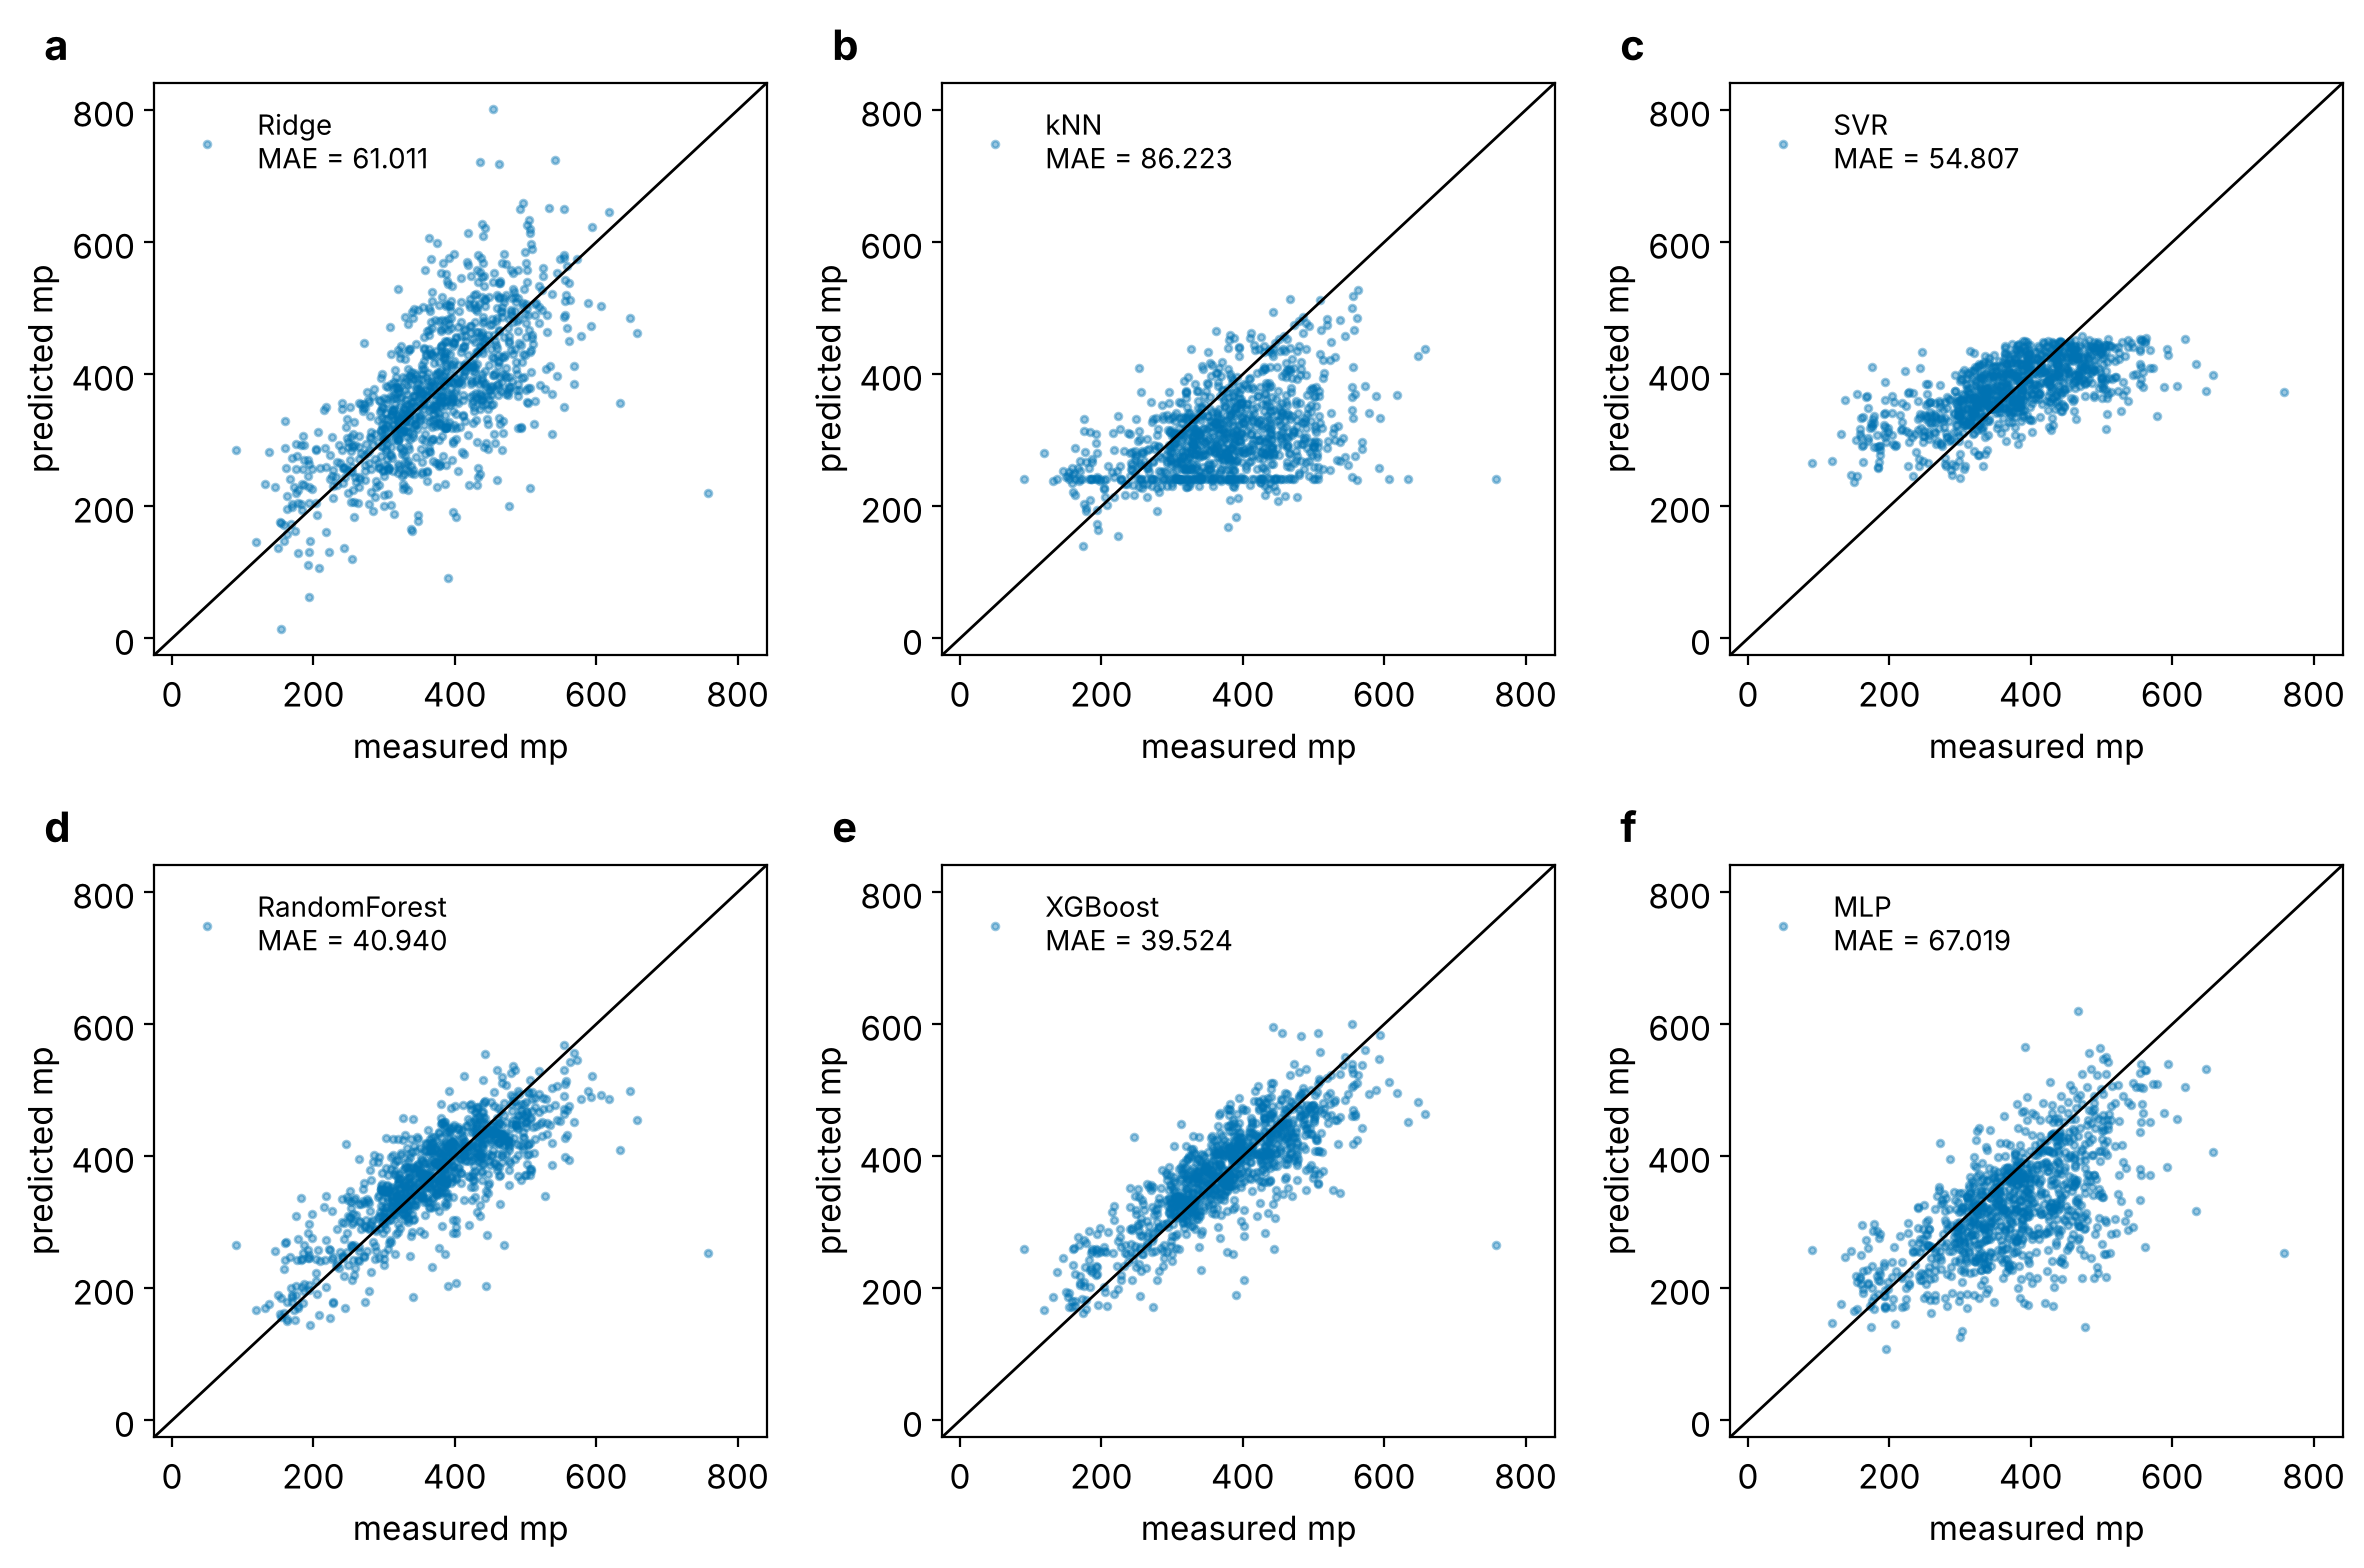

In [12]:
def parity_grid(split_name, feat_name):
    names = list(get_models())
    fig, axes = plt.subplots(2, 3, figsize=(12, 8))
    allv = np.concatenate([np.r_[preds[(split_name, feat_name, n)]].ravel() for n in names])
    lo, hi = allv.min(), allv.max(); pad = 0.05 * (hi - lo); lim = (lo - pad, hi + pad)
    for ax, (tag, name) in zip(axes.flat, zip('abcdef', names)):
        yt, yp = preds[(split_name, feat_name, name)]
        mae = mean_absolute_error(yt, yp)
        ax.scatter(yt, yp, s=6, alpha=0.4, color='#0072B2', label=f'{name}\nMAE = {mae:.3f}')
        ax.plot(lim, lim, color='k', lw=1)
        ax.set_xlim(lim); ax.set_ylim(lim)
        ax.set_xlabel(f'measured {PROP}'); ax.set_ylabel(f'predicted {PROP}')
        ax.legend(loc='upper left', frameon=False, fontsize=10)
        ax.text(-0.18, 1.04, tag, transform=ax.transAxes, fontsize=15, fontweight='bold')
        n_out = ((yt < lim[0]) | (yt > lim[1]) | (yp < lim[0]) | (yp > lim[1])).sum()
        if n_out: print(f'{name}: 축 범위 밖 점 {n_out}개')
    plt.tight_layout(); plt.show()

parity_grid('random', 'MorganFP')

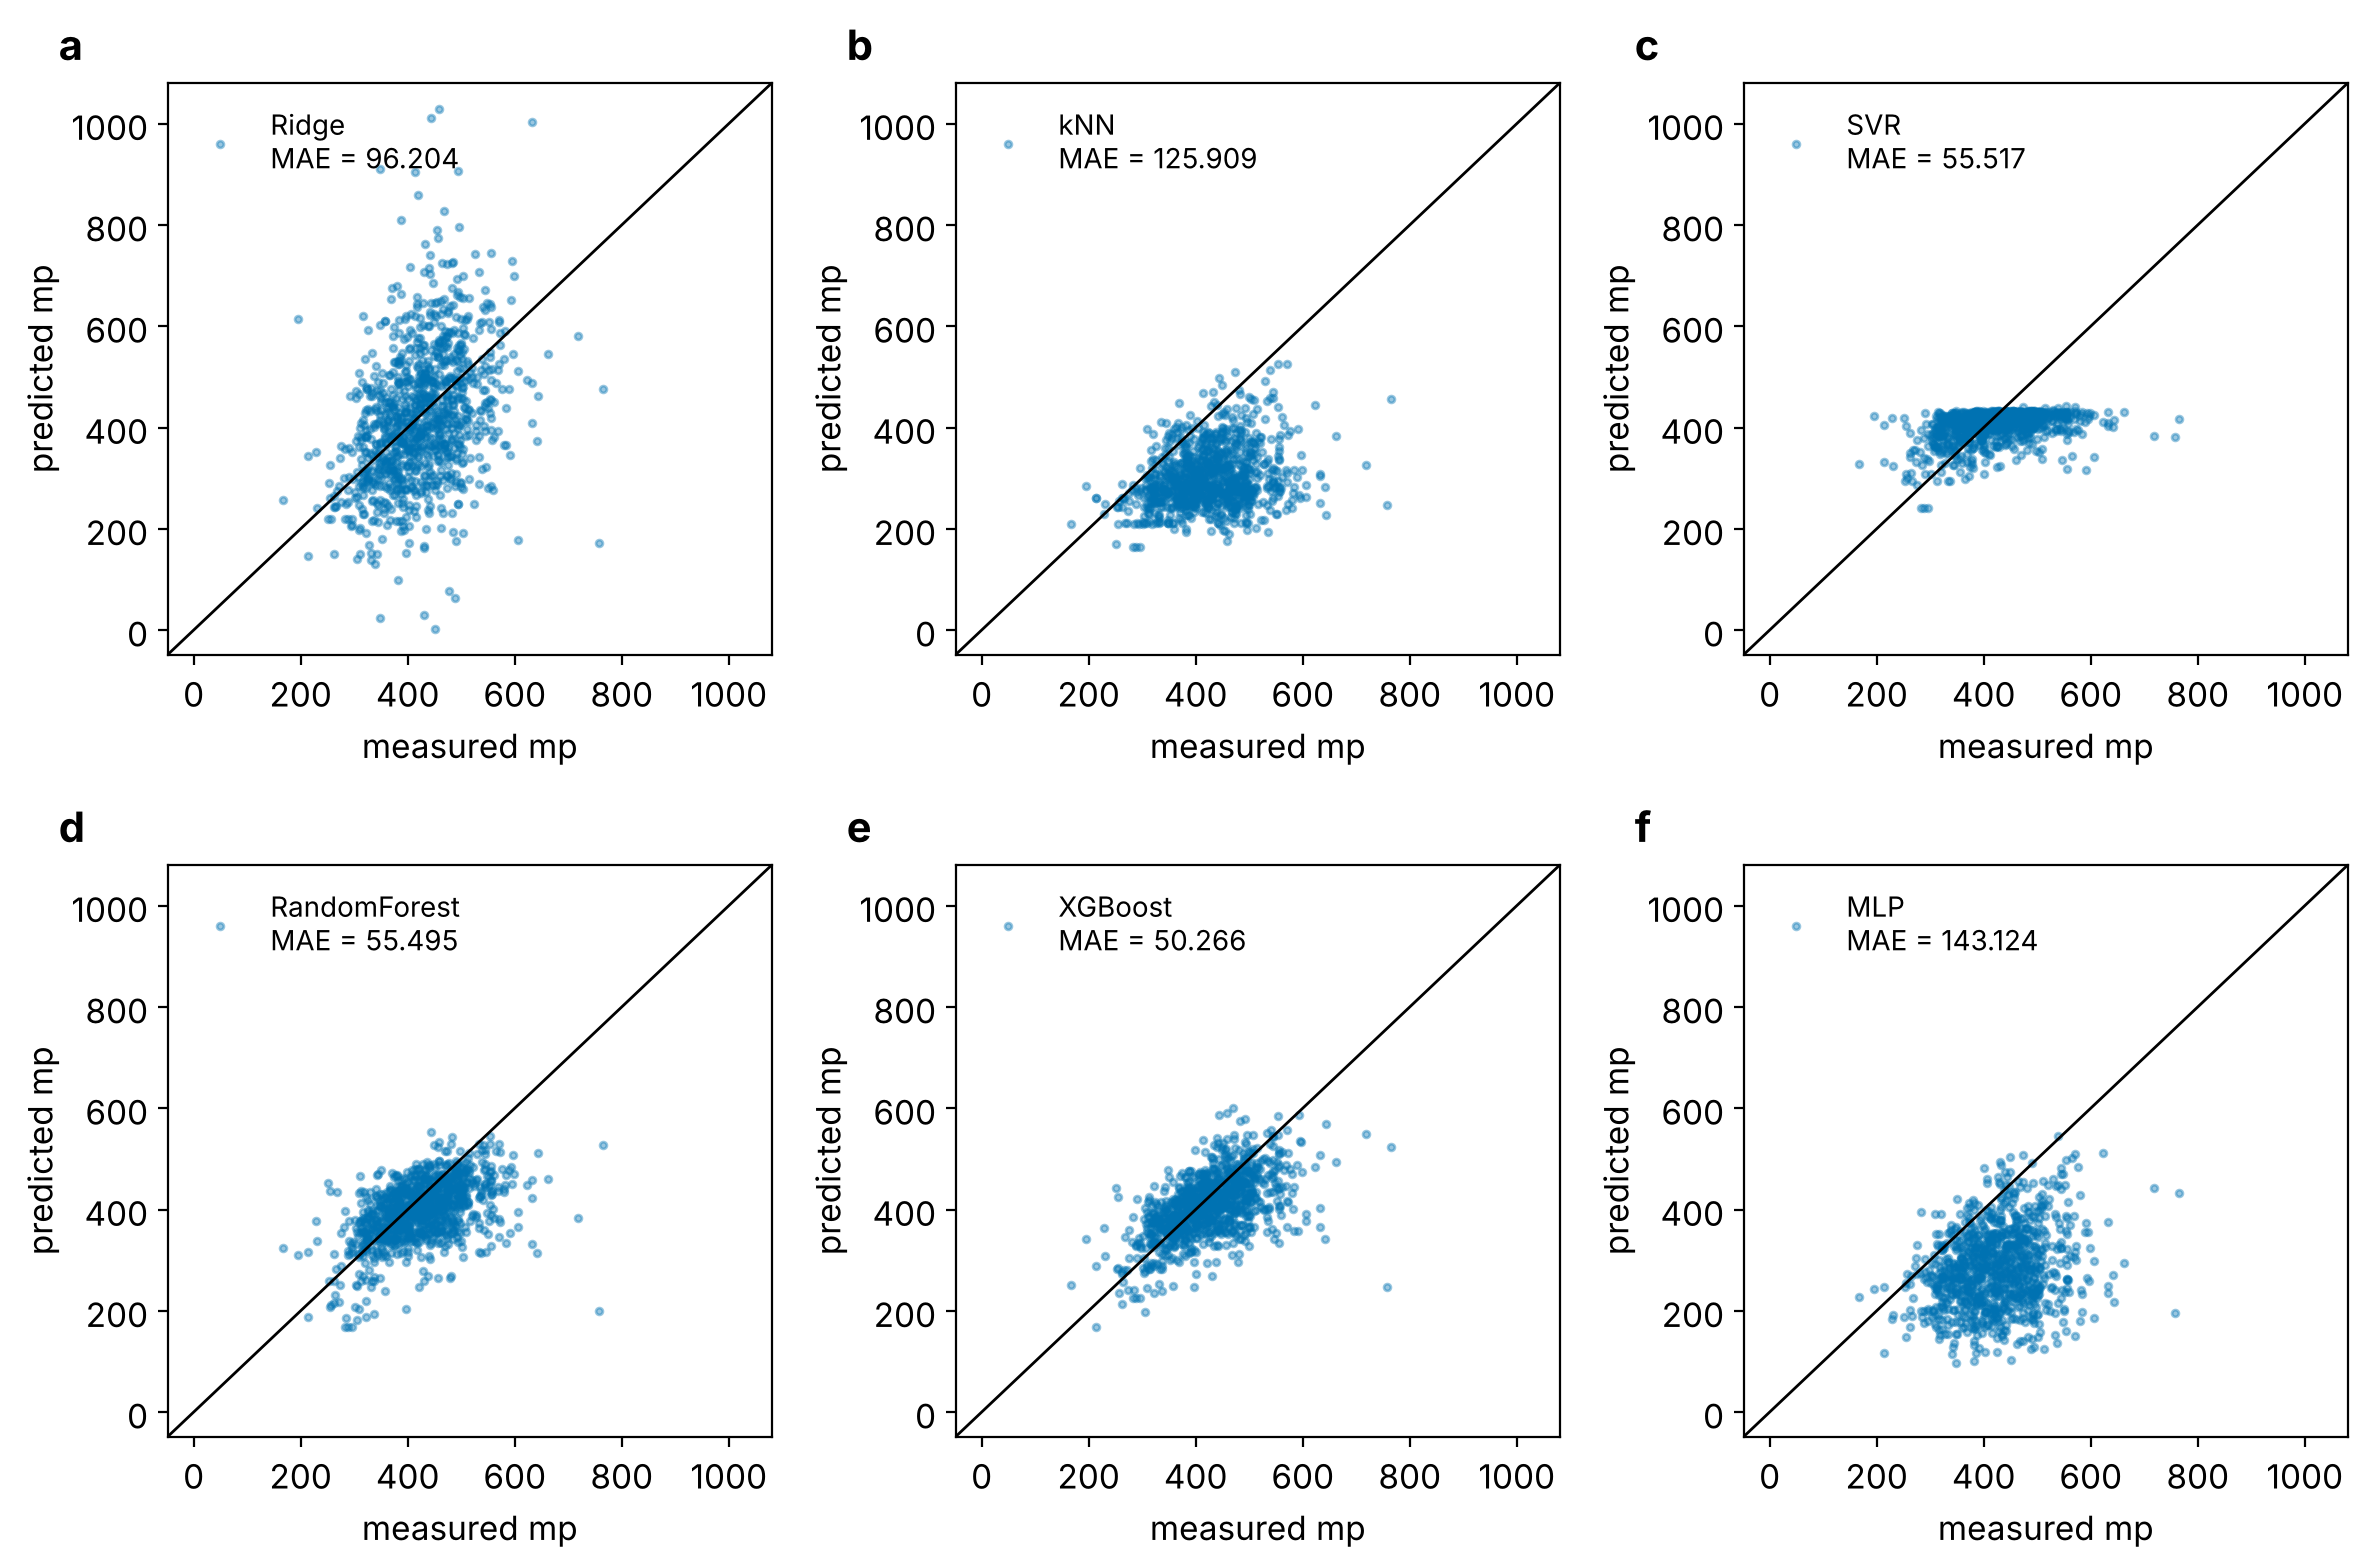

In [13]:
parity_grid('scaffold', 'MorganFP')

## 8. random vs scaffold 한눈에
막대가 길수록 오차가 크다. 두 분할의 차이가 크면 그 모델은 **본 적 있는 뼈대를 외운 것**에 가깝다.

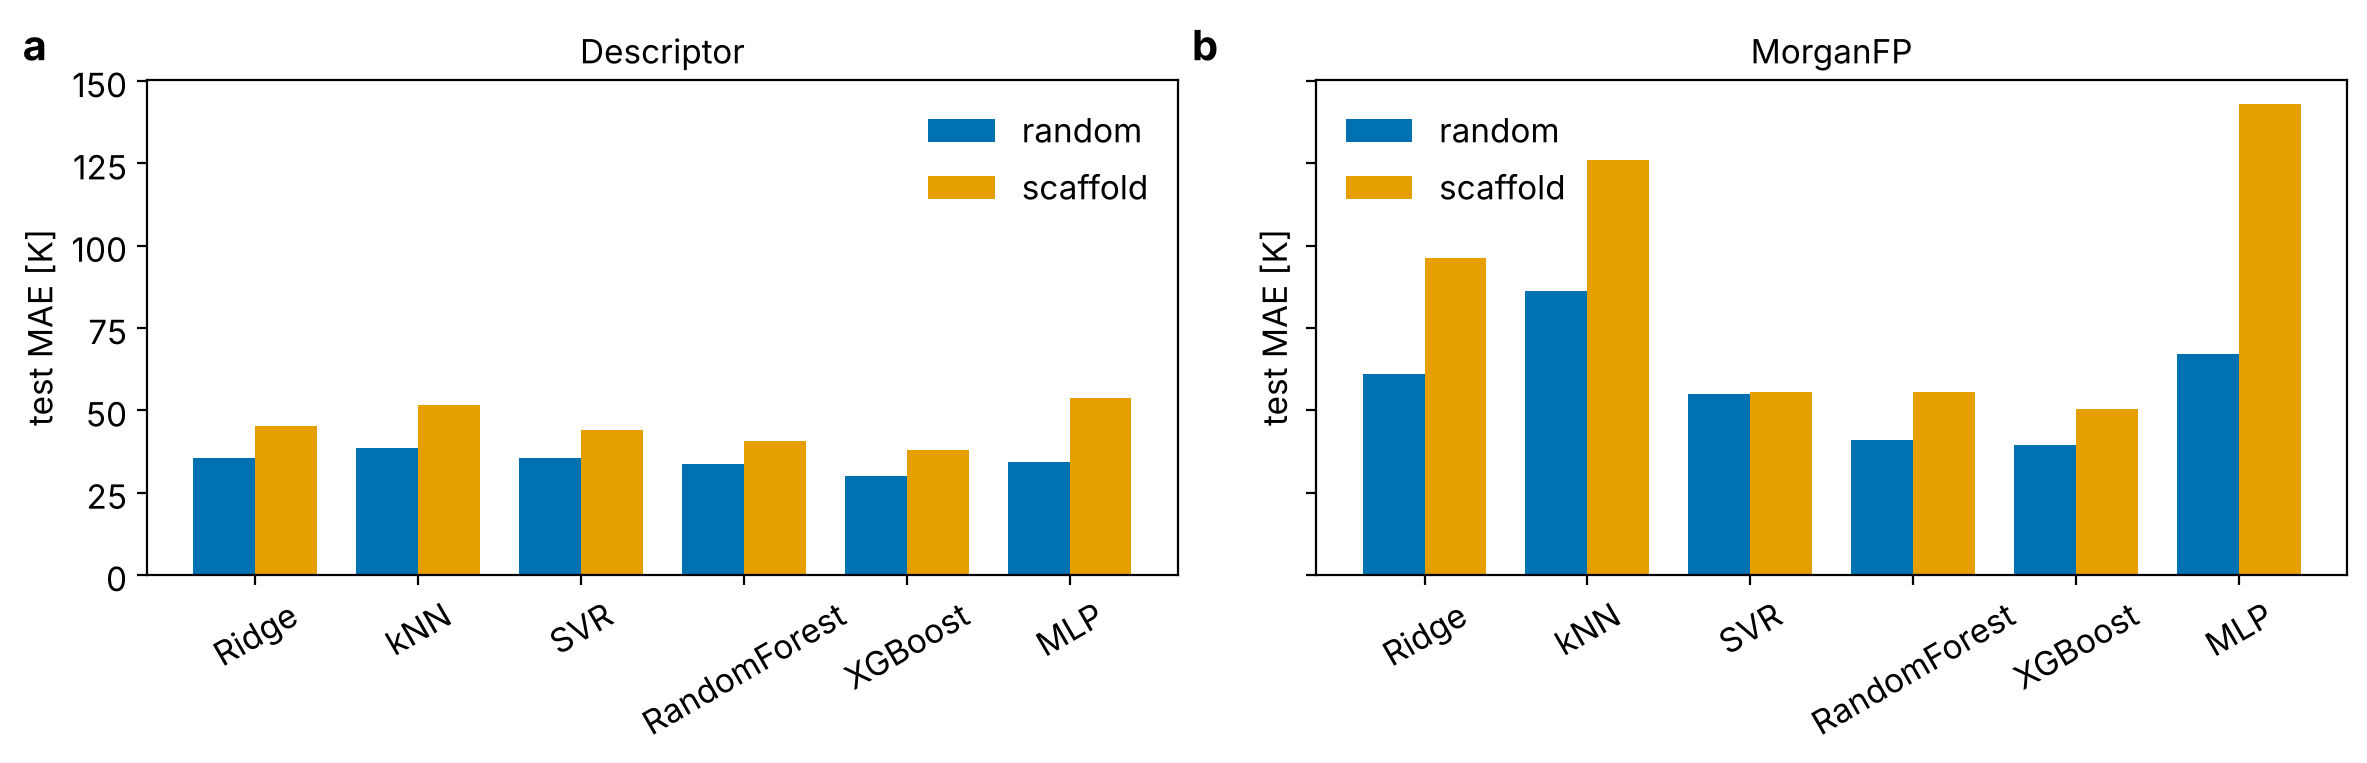

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (tag, feat) in zip(axes, zip('ab', features)):
    sub = res[res.feature == feat].pivot(index='model', columns='split', values='MAE')
    sub = sub.loc[list(get_models())]
    x = np.arange(len(sub)); w = 0.38
    ax.bar(x - w/2, sub['random'], w, color='#0072B2', label='random')
    ax.bar(x + w/2, sub['scaffold'], w, color='#E69F00', label='scaffold')
    ax.set_xticks(x); ax.set_xticklabels(sub.index, rotation=30)
    ax.set_ylabel(f'test MAE [{unit}]'); ax.set_title(feat, fontsize=12)
    ax.legend(frameon=False)
    ax.text(-0.12, 1.04, tag, transform=ax.transAxes, fontsize=15, fontweight='bold')
plt.tight_layout(); plt.show()

## 9. 팀 과제 (다음 시간 5분 발표)
1. **결과표 한 장**: 우리 팀 물성에서 가장 좋은 조합(표현 + 모델)과 가장 나쁜 조합. 기준선 MAE와 비교
2. **random vs scaffold**: 차이가 가장 큰 모델은 무엇이고, 왜 그렇다고 생각하는가
3. **하나만 바꿔보기** (택 1)
   - `MAX_N = None`으로 전체 데이터 사용 → 성능이 얼마나 오르나 (learning curve)
   - Morgan `radius`를 1, 2, 3으로 바꾸기
   - descriptor + fingerprint를 이어 붙이기 (`np.hstack`)
   - (logP 팀) descriptor에서 `MolLogP` 열을 빼고 다시 돌리기 → 성능이 얼마나 떨어지나. 그 차이가 무엇을 뜻하나
   - Random Forest의 `feature_importances_` 상위 10개 descriptor를 뽑고 화학적으로 해석하기
4. **틀린 분자 보기**: 오차가 가장 큰 분자 5개의 SMILES를 그려보고 공통점 찾기 (아래 셀)

**규칙**: 시험 세트 성능을 보고 하이퍼파라미터를 고르지 않는다. 튜닝이 필요하면 학습 세트 안에서 교차검증(`cross_val_score`)으로 한다.

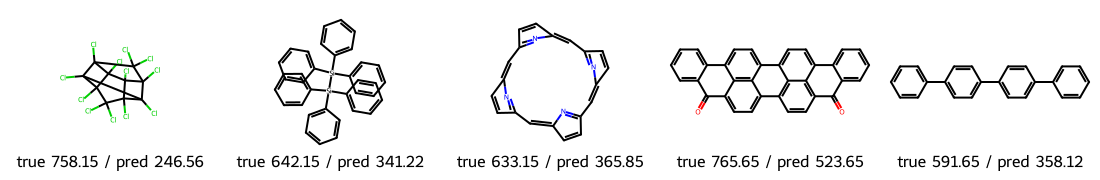

In [15]:
from rdkit.Chem import Draw
yt, yp = preds[('scaffold', 'MorganFP', 'XGBoost')]
te = splits['scaffold'][1]
worst = np.argsort(-np.abs(yt - yp))[:5]
Draw.MolsToGridImage([df['mol'][te[i]] for i in worst], molsPerRow=5, subImgSize=(220, 180),
                     legends=[f'true {yt[i]:.2f} / pred {yp[i]:.2f}' for i in worst])

## [추가 — mp 팀] 발표 재료 저장 (교수님 코드 아님)
결과표·기준선·24개 조합의 test 예측을 `results_nb_mp/` 에 저장하고, Descriptor parity 와 XGBoost SHAP / RF 중요도(§9 선택 과제)를 계산한다.

In [16]:
# 위 "틀린 분자 5개" 그림 저장 (scaffold / MorganFP / XGBoost)
img = Draw.MolsToGridImage([df['mol'][te[i]] for i in worst], molsPerRow=5, subImgSize=(220, 180),
                           legends=[f'true {yt[i]:.1f} / pred {yp[i]:.1f} K' for i in worst])
path = f'{OUT}/fig07_worst5_XGBoost_MorganFP_scaffold.png'
if hasattr(img, 'save'):
    img.save(path)
else:
    open(path, 'wb').write(img.data)
print('saved', path)

saved results_nb_mp/fig07_worst5_XGBoost_MorganFP_scaffold.png


In [17]:
import json
res.to_csv(f'{OUT}/results_mp.csv', index=False)
table_out = table.sort_values('random')
table_out.to_csv(f'{OUT}/mae_table_mp.csv')
info = {'PROP': PROP, 'MAX_N': MAX_N, 'SEED': SEED, 'n_rows': int(len(df)), 'unit': unit,
        'baseline_MAE': {k: float(v) for k, v in base.items()},
        'n_desc': int(X_desc.shape[1]), 'fp_bits_mean': float(X_fp.sum(1).mean()),
        'fp_bits_min': int(X_fp.sum(1).min()), 'fp_bits_max': int(X_fp.sum(1).max()),
        'splits': {k: {'train': int(len(tr)), 'test': int(len(te))} for k, (tr, te) in splits.items()},
        'n_scaffolds_total': int(len(set(MurckoScaffold.MurckoScaffoldSmiles(mol=m, includeChirality=False) for m in df['mol']))),
        'y_describe': {k: float(v) for k, v in df['value'].describe().items()}}
# scaffold split 의 test 골격 수, train 과 겹치는 골격 수 (14쪽: test 는 처음 보는 골격인가)
scaf = [MurckoScaffold.MurckoScaffoldSmiles(mol=m, includeChirality=False) for m in df['mol']]
for k, (tr, te) in splits.items():
    s_tr, s_te = set(scaf[i] for i in tr), set(scaf[i] for i in te)
    info['splits'][k].update(n_scaffold_train=len(s_tr), n_scaffold_test=len(s_te), n_scaffold_overlap=len(s_tr & s_te),
                             frac_test_mols_with_seen_scaffold=float(np.mean([scaf[i] in s_tr for i in te])))
json.dump(info, open(f'{OUT}/run_info.json', 'w', encoding='utf-8'), indent=2, ensure_ascii=False)
for (split_, feat_, model_), (yt_, yp_) in preds.items():
    tr_, te_ = splits[split_]
    pd.DataFrame({'smiles': df['smiles'].values[te_], 'y_true': yt_, 'y_pred': yp_, 'train_mean': y[tr_].mean()}
                 ).to_csv(f'{OUT}/pred_test_{model_}_{feat_}_{split_}.csv', index=False)
print(json.dumps(info, indent=2, ensure_ascii=False))

{
  "PROP": "mp",
  "MAX_N": 5000,
  "SEED": 42,
  "n_rows": 5000,
  "unit": "K",
  "baseline_MAE": {
    "random": 72.51339228999998,
    "scaffold": 75.95917086000004
  },
  "n_desc": 217,
  "fp_bits_mean": 25.9452,
  "fp_bits_min": 1,
  "fp_bits_max": 95,
  "splits": {
    "random": {
      "train": 4000,
      "test": 1000,
      "n_scaffold_train": 1204,
      "n_scaffold_test": 385,
      "n_scaffold_overlap": 180,
      "frac_test_mols_with_seen_scaffold": 0.79
    },
    "scaffold": {
      "train": 4000,
      "test": 1000,
      "n_scaffold_train": 409,
      "n_scaffold_test": 1000,
      "n_scaffold_overlap": 0,
      "frac_test_mols_with_seen_scaffold": 0.0
    }
  },
  "n_scaffolds_total": 1409,
  "y_describe": {
    "count": 5000.0,
    "mean": 377.41888800000004,
    "std": 92.29944372051047,
    "min": 80.14999999999998,
    "25%": 319.15,
    "50%": 378.15,
    "75%": 441.15,
    "max": 790.15
  }
}


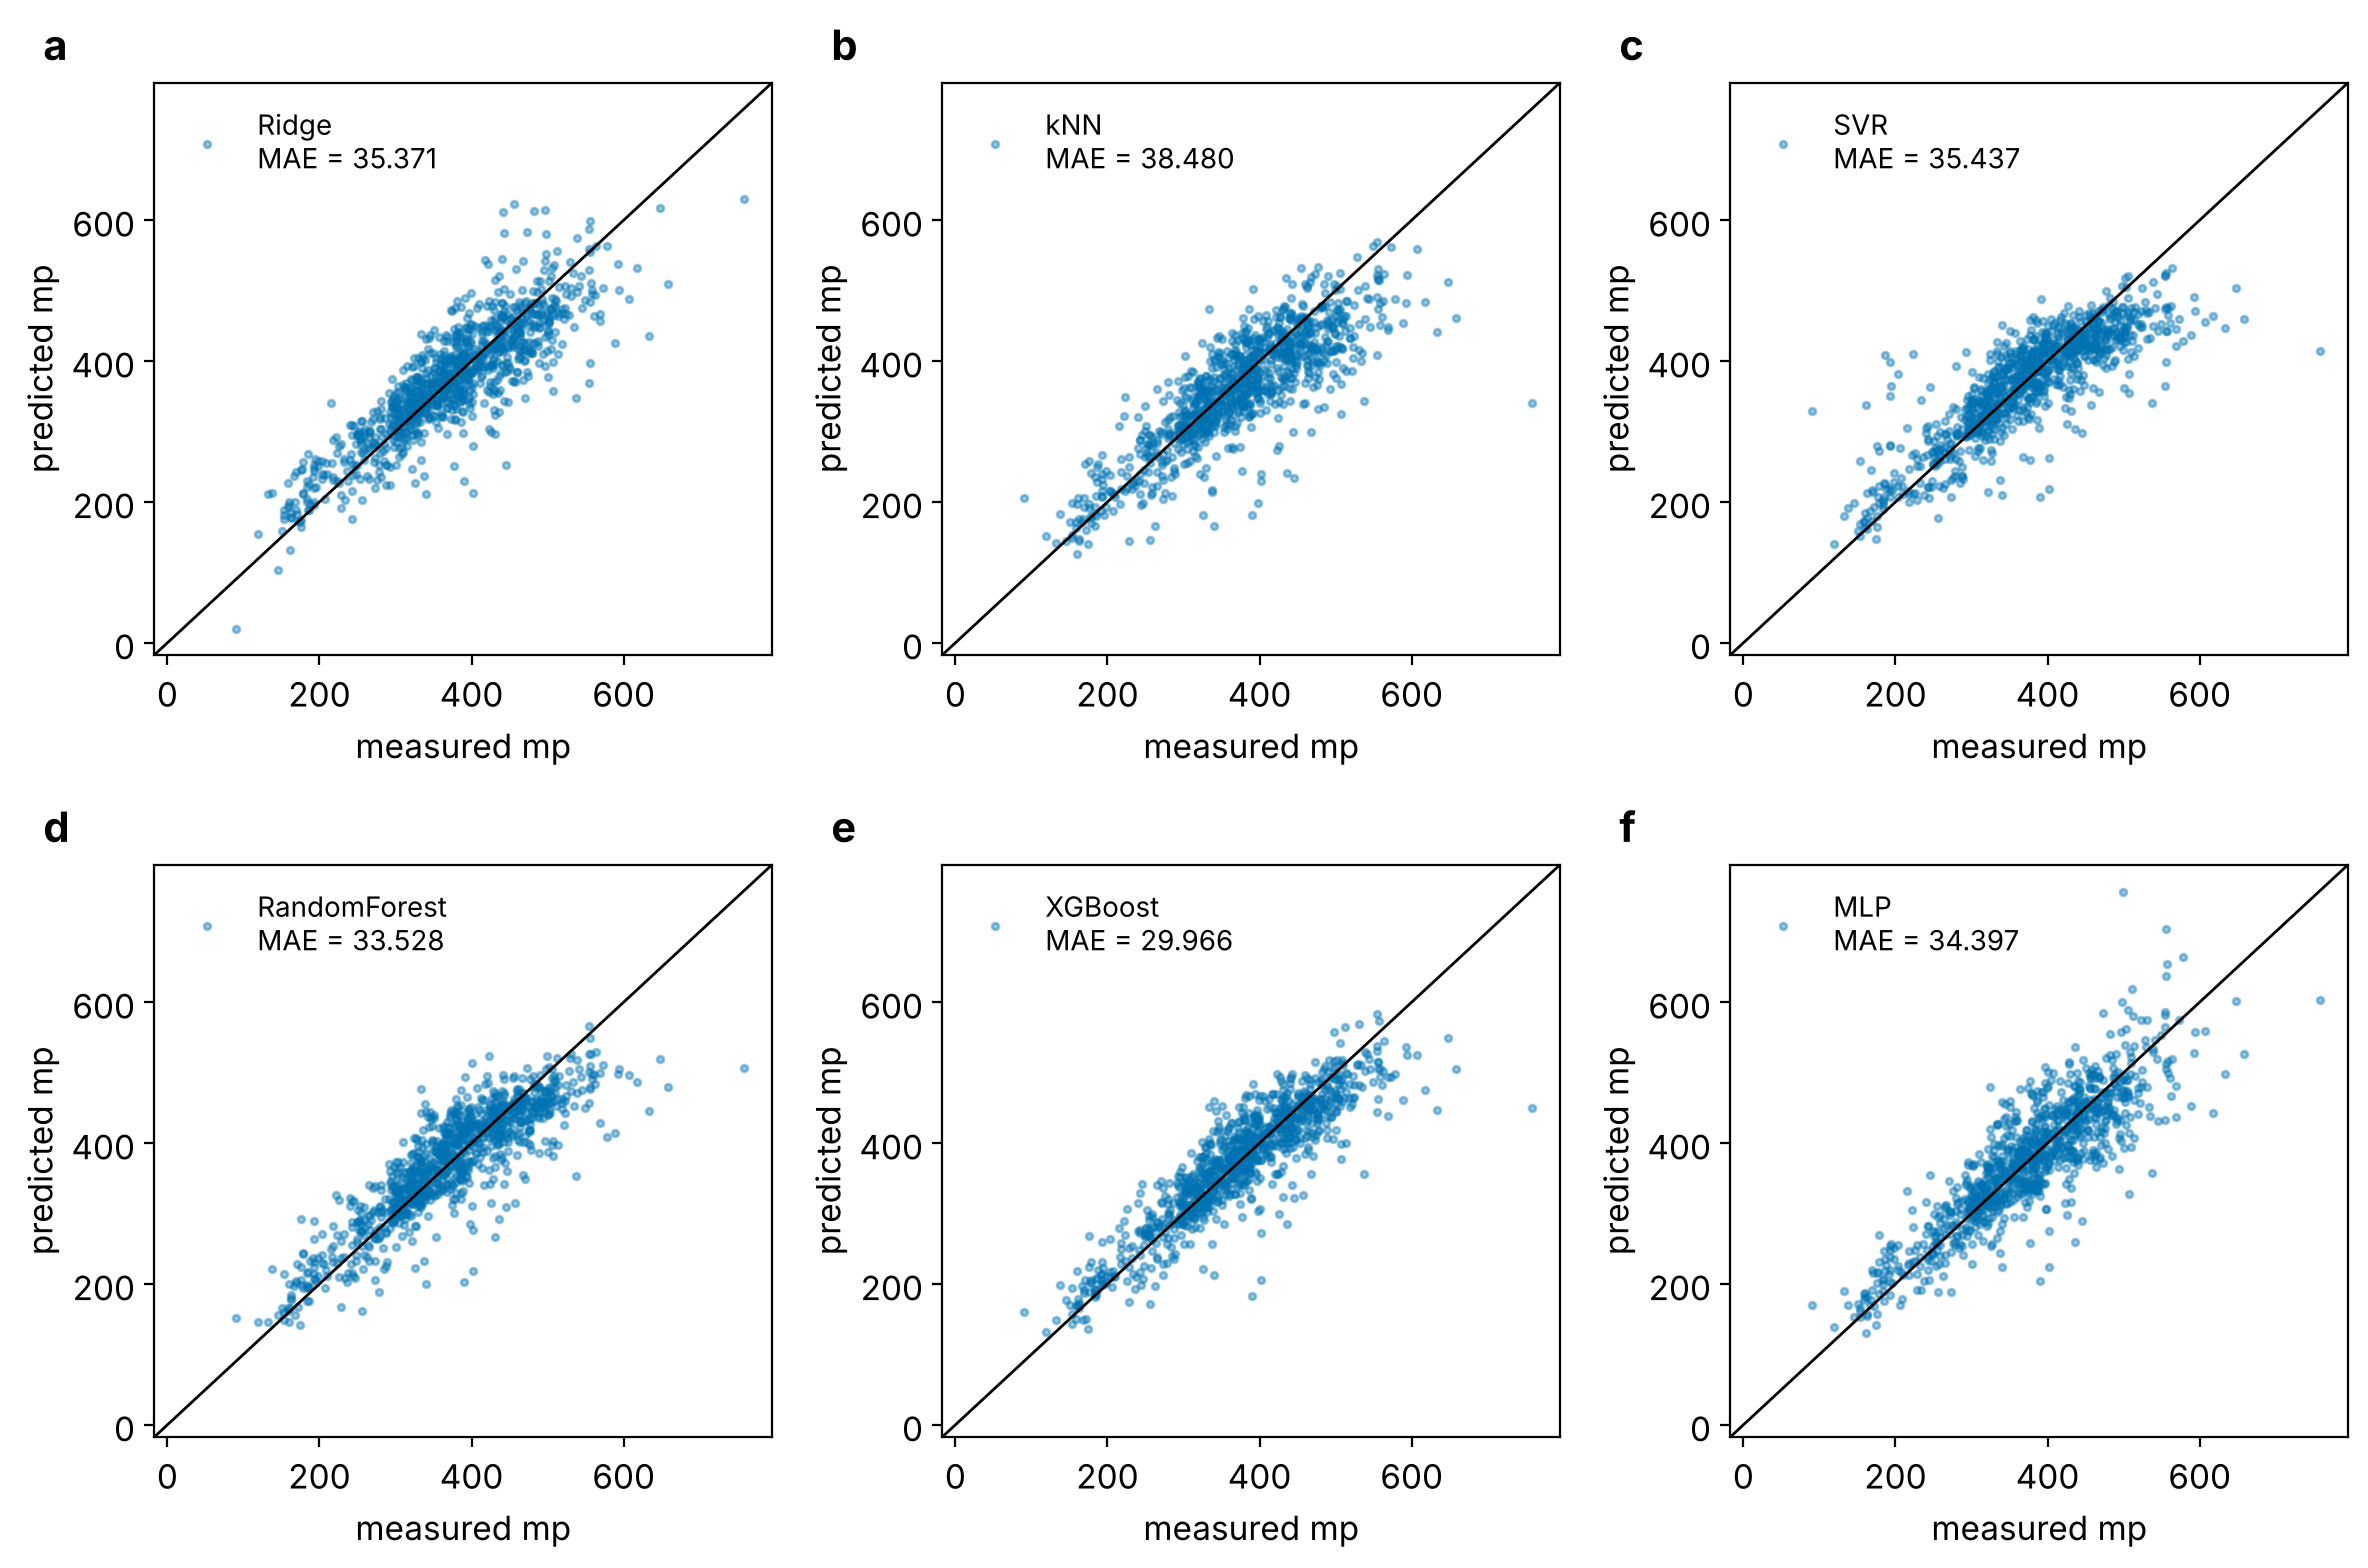

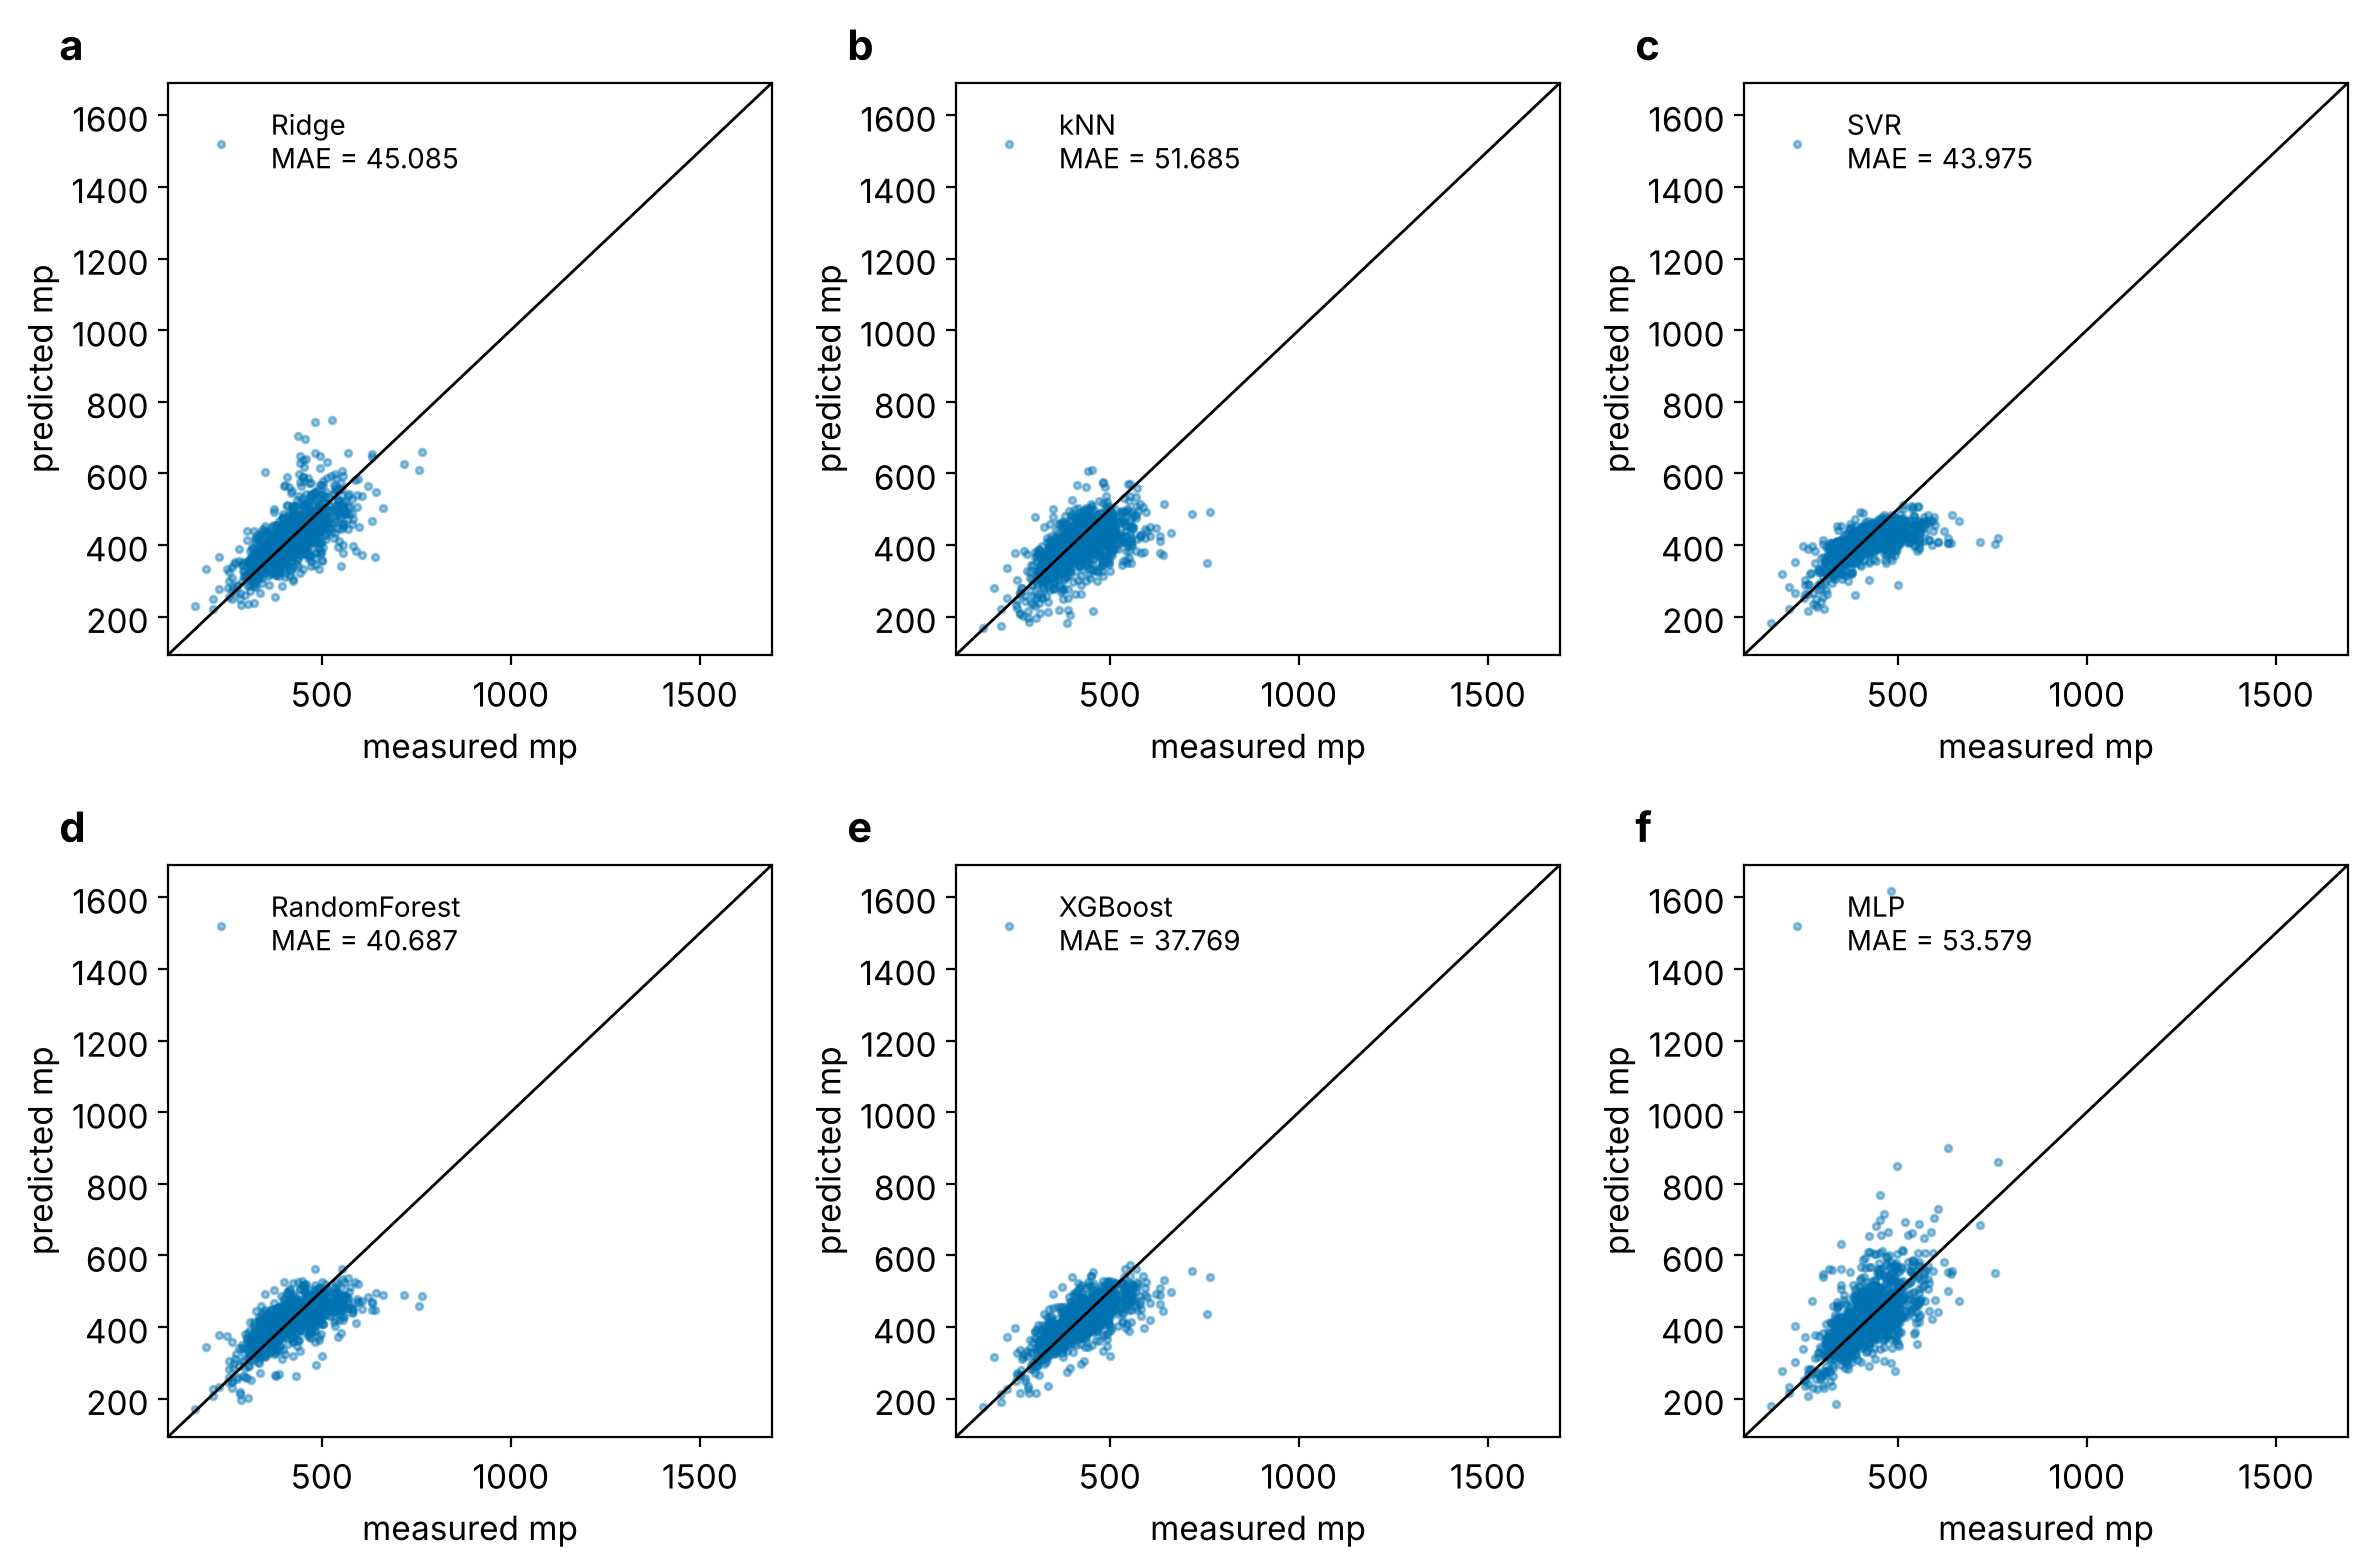

In [18]:
# Descriptor 표현의 parity (본문은 MorganFP 만 그렸다)
parity_grid('random', 'Descriptor')
parity_grid('scaffold', 'Descriptor')

In [19]:
# §9 선택 과제: RF feature_importances_ 상위 10 descriptor + XGBoost SHAP (두 분할, Descriptor 표현)
# 루프 안의 모델은 버려지므로 같은 설정·같은 seed 로 다시 fit 한다 (결정적 → 결과표의 모델과 같다).
import shap
xai = {}
for split_name in splits:
    tr, te = splits[split_name]
    rf = get_models()['RandomForest'].fit(X_desc[tr], y[tr])
    imp = pd.Series(rf.feature_importances_, index=desc_names).sort_values(ascending=False)
    imp.head(30).to_csv(f'{OUT}/rf_importance_Descriptor_{split_name}.csv', header=['importance'])
    xgb = get_models()['XGBoost'].fit(X_desc[tr], y[tr])
    print(split_name, 'refit XGBoost vs 결과표 예측 최대 차이 [K]:', float(np.abs(xgb.predict(X_desc[te]) - preds[(split_name, 'Descriptor', 'XGBoost')][1]).max()))
    sv = shap.TreeExplainer(xgb).shap_values(X_desc[te])
    mean_abs = np.abs(sv).mean(0)
    order = np.argsort(-mean_abs)[:20]
    rows_x = []
    for j in order:
        xj, sj = X_desc[te][:, j], sv[:, j]
        corr = np.corrcoef(xj, sj)[0, 1] if xj.std() > 0 and sj.std() > 0 else np.nan
        rows_x.append(dict(feature=desc_names[j], mean_abs_shap_K=mean_abs[j], corr_value_vs_shap=corr,
                           direction=('값 커지면 mp ↑' if corr > 0.2 else '값 커지면 mp ↓' if corr < -0.2 else '단조적이지 않음')))
    pd.DataFrame(rows_x).to_csv(f'{OUT}/shap_top20_XGBoost_Descriptor_{split_name}.csv', index=False)
    xai[split_name] = (imp.head(10), pd.DataFrame(rows_x).head(10))
    plt.figure()
    shap.summary_plot(sv, X_desc[te], feature_names=desc_names, max_display=15, show=False)
    plt.title(f'XGBoost + Descriptor, {split_name} test (n={len(te)}), SHAP [K]')
    plt.gcf().savefig(f'{OUT}/fig08_shap_beeswarm_XGBoost_Descriptor_{split_name}.png', dpi=150, bbox_inches='tight'); plt.close()
    plt.figure()
    shap.summary_plot(sv, X_desc[te], feature_names=desc_names, max_display=15, plot_type='bar', show=False)
    plt.title(f'XGBoost + Descriptor, {split_name} test, mean |SHAP| [K]')
    plt.gcf().savefig(f'{OUT}/fig09_shap_bar_XGBoost_Descriptor_{split_name}.png', dpi=150, bbox_inches='tight'); plt.close()
for split_name, (imp10, sh10) in xai.items():
    print(f'\n=== {split_name}: RF importance top 10 ===\n{imp10.round(4).to_string()}')
    print(f'\n=== {split_name}: XGBoost SHAP top 10 ===\n{sh10.round(3).to_string(index=False)}')

random refit XGBoost vs 결과표 예측 최대 차이 [K]: 0.0


scaffold refit XGBoost vs 결과표 예측 최대 차이 [K]: 0.0



=== random: RF importance top 10 ===
BertzCT              0.3281
TPSA                 0.1041
NumHDonors           0.0678
RingCount            0.0582
NHOHCount            0.0330
FractionCSP3         0.0142
BCUT2D_MRHI          0.0129
MolLogP              0.0091
NumRotatableBonds    0.0090
VSA_EState2          0.0084

=== random: XGBoost SHAP top 10 ===
          feature  mean_abs_shap_K  corr_value_vs_shap  direction
          BertzCT        19.188999               0.826 값 커지면 mp ↑
             TPSA        15.926000               0.830 값 커지면 mp ↑
        RingCount         9.844000               0.952 값 커지면 mp ↑
       NumHDonors         8.530000               0.820 값 커지면 mp ↑
        NHOHCount         5.753000               0.822 값 커지면 mp ↑
NumRotatableBonds         4.840000              -0.807 값 커지면 mp ↓
     FractionCSP3         4.233000              -0.837 값 커지면 mp ↓
      fr_bicyclic         3.113000               0.822 값 커지면 mp ↑
 FpDensityMorgan3         3.078000              -0.